In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import json

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../data/processed/cleaned_telco_churn.csv"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [3]:
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (5634, 19)
Testing data: (1409, 19)

Training churn distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [6]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\navka\AppData\Local\Temp\ipykernel_1540\2989966197.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [8]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Non-churn customers:", negative_count)
print("Churn customers:", positive_count)
print("XGBoost scale_pos_weight:", scale_pos_weight)

Non-churn customers: 4139
Churn customers: 1495
XGBoost scale_pos_weight: 2.768561872909699


In [9]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("All four models initialized successfully!")

All four models initialized successfully!


In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():

    print(f"\nTraining and evaluating: {name}")

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("classifier", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

    print("Completed:", name)

print("\nAll models evaluated successfully!")


Training and evaluating: Logistic Regression
Completed: Logistic Regression

Training and evaluating: Decision Tree
Completed: Decision Tree

Training and evaluating: Random Forest
Completed: Random Forest

Training and evaluating: XGBoost
Completed: XGBoost

All models evaluated successfully!


In [11]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["F1 Score", "Recall"],
    ascending=False
)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
3              XGBoost    0.7606     0.5338  0.7719    0.6310   0.8430
0  Logistic Regression    0.7485     0.5169  0.8013    0.6283   0.8460
2        Random Forest    0.7854     0.6273  0.4716    0.5380   0.8223
1        Decision Tree    0.7364     0.5040  0.4870    0.4951   0.6570


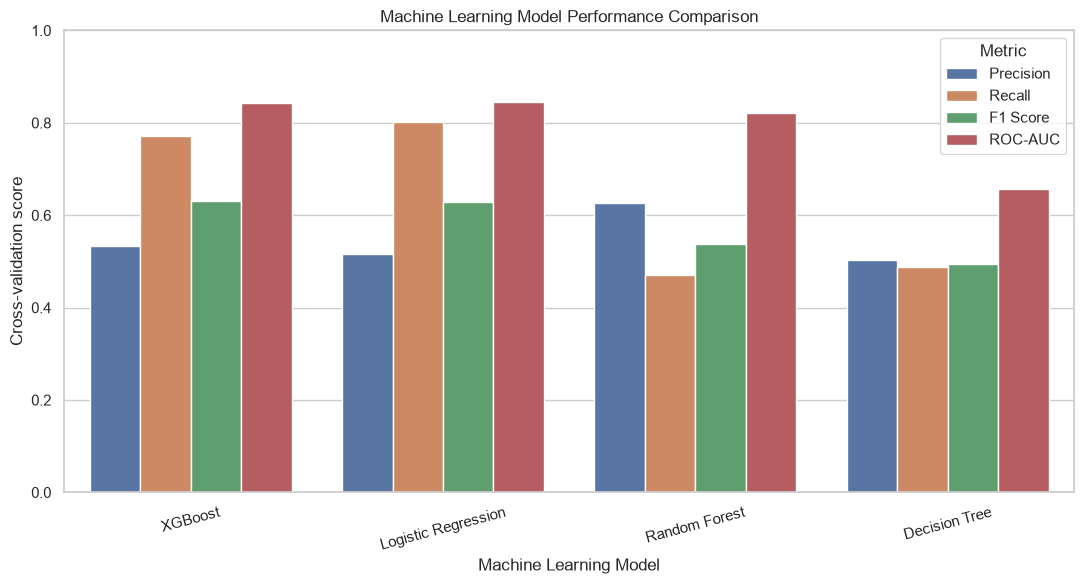

In [12]:
plt.figure(figsize=(11, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1 Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Cross-validation score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [13]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model based on cross-validation:")
print(best_model_name)

Best model based on cross-validation:
XGBoost


In [14]:
best_pipeline = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("classifier", clone(models[best_model_name]))
])

best_pipeline.fit(X_train, y_train)

print("Selected model trained successfully!")

Selected model trained successfully!


In [15]:
y_pred = best_pipeline.predict(X_test)

y_probability = best_pipeline.predict_proba(X_test)[:, 1]

In [16]:
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

print("Selected model:", best_model_name)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

Selected model: XGBoost
Accuracy: 0.7544
Precision: 0.5255
Recall: 0.7727
F1 Score: 0.6255
ROC-AUC: 0.8419


In [17]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.77      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



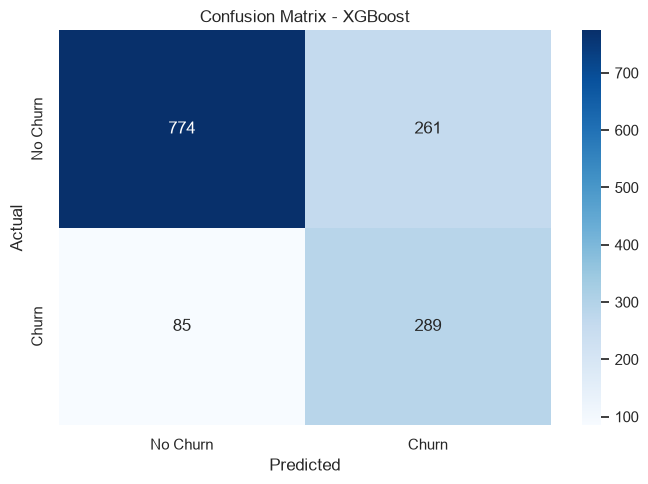

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

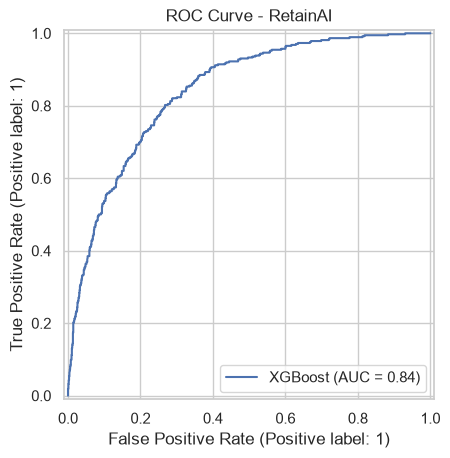

In [19]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    name=best_model_name
)

plt.title("ROC Curve - RetainAI")
plt.grid(True)
plt.show()

In [20]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/model", exist_ok=True)

# Save complete model pipeline
joblib.dump(
    best_pipeline,
    "../models/churn_model_pipeline.joblib"
)

# Save model comparison results
results_df.to_csv(
    "../reports/model/model_comparison.csv",
    index=False
)

# Save final test metrics
with open("../reports/model/test_metrics.json", "w") as file:
    json.dump({
        "selected_model": best_model_name,
        "test_metrics": test_metrics
    }, file, indent=4)

print("Model pipeline saved successfully!")
print("Model comparison report saved!")
print("Test metrics saved!")

Model pipeline saved successfully!
Model comparison report saved!
Test metrics saved!


In [21]:
loaded_model = joblib.load(
    "../models/churn_model_pipeline.joblib"
)

sample_customer = X_test.iloc[[0]]

sample_prediction = loaded_model.predict(sample_customer)[0]

sample_probability = loaded_model.predict_proba(
    sample_customer
)[0][1]

print("Prediction:", "Churn" if sample_prediction == 1 else "No Churn")
print(f"Churn probability: {sample_probability:.2%}")

Prediction: No Churn
Churn probability: 1.40%
